# Experiment 03_7 — ConvNeXt-Tiny Full Fine-Tuning & Smart White-Border Cropping

Minimalistisches Optimierungs-Notebook für `ConvNeXt-Tiny` basierend auf den Erkenntnissen aus `03_2` bis `03_6`:
1. **Smart White-Border Cropping (`SmartWhiteBorderCrop`)**: Prüft zuerst, ob ein großer weißer Rand vorliegt (`bbox_ratio < 0.75`), und schneidet kleine Objekte direkt als natives `224x224`-Fenster aus, statt das gesamte `500x500`-Bild herunterzuskalieren.
2. **Full Fine-Tuning mit 4-stufigen Lernraten**: Nach 1 Warmup-Epoche für den Klassifikationskopf wird das **gesamte** `ConvNeXt-Tiny`-Netzwerk (`features[0..7]` + `classifier`) mit schichtweise abgestuften Lernraten (`1e-5` bis `1e-4`) trainiert.
3. **Gezieltes Minority-Handling ohne Augmentation-Leakage**: Gleiche produkt-schonende Augmentierung für alle Klassen kombiniert mit gedämpftem `WeightedRandomSampler` (`power=0.25`), damit unterrepräsentierte Klassen pro Epoche häufiger und stärker variiert gesehen werden.

## 1. Configuration

In [1]:
import json
import random
import shutil
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from tqdm import tqdm

# =============================================================================
# GEPLANTE SCHRITTE & IDEEN (ÜBERSICHT):
# 1. Smart White-Border Cropping:
#    - Prüft per Bounding-Box, ob das Produkt von einem großen weißen Rand
#      umgeben ist (bbox_ratio < 0.75, d.h. > 25% weißer Rand).
#    - Ist das Objekt kleiner als 224x224 Pixel, wird ein natives 224x224
#      Fenster um das Objekt ausgeschnitten (Cropping statt Verkleinern!).
# 2. Full Fine-Tuning (ConvNeXt-Tiny):
#    - Phase 1 (1 Epoche) : Warmup nur für den neuen Classifier-Head.
#    - Phase 2 (6 Epochen): Full Fine-Tuning aller Backbone-Blöcke (features 0..7)
#      mit 4-stufigem Layer-wise Learning Rate Decay + CosineAnnealingLR.
# 3. Unterrepräsentierte Klassen & Augmentierung:
#    - Keine exklusive Augmentierung nur für kleine Klassen (verhindert, dass
#      das Netz Augmentierungs-Artefakte als Shortcut für seltene Klassen lernt).
#    - Stattdessen: Einheitliche Augmentierung + gedämpfter WeightedRandomSampler,
#      sodass seltene Klassen häufiger gezogen und jedes Mal neu augmentiert werden.
# =============================================================================

IN_COLAB                 = 'google.colab' in sys.modules
RANDOM_STATE             = 42
BATCH_SIZE               = 32
NUM_WORKERS              = 2 if IN_COLAB else 8
EXPECTED_VALIDATION_ROWS = 16_984

# Schritt 1: Smart-Cropping Parameter (nur croppen wenn Objekt < 75% der Bildfläche)
WHITE_THRESHOLD          = 245
CROP_PADDING             = 12
MAX_BBOX_RATIO           = 0.75
MIN_CROP_SIZE            = 224

# Schritt 2: 2-Phasen Full-Finetuning mit 4-stufigen Lernraten (Early -> Stage3 -> Stage4 -> Head)
HEAD_EPOCHS              = 1
FINETUNE_EPOCHS          = 6
HEAD_WARMUP_LR           = 5e-4
HEAD_FINETUNE_LR         = 1e-4
STAGE4_LEARNING_RATE     = 8e-5
STAGE3_LEARNING_RATE     = 3e-5
EARLY_LEARNING_RATE      = 1e-5
MIN_LEARNING_RATE        = 1e-6

# Schritt 3: Regularisierung & Minority-Class Balancing (Sampler + sanfte Loss-Gewichte)
WEIGHT_DECAY             = 2e-4
LABEL_SMOOTHING          = 0.10
SAMPLER_POWER            = 0.25
CLASS_WEIGHT_POWER       = 0.15
EARLY_STOPPING_PATIENCE  = 2
USE_TTA_IN_FINAL_EVAL    = True

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    DRIVE_DIR            = Path('/content/drive/MyDrive/rakuten_colab')
    IMAGE_ZIP_PATH       = DRIVE_DIR / 'image_train.zip'
    MANIFEST_DRIVE_PATH  = DRIVE_DIR / 'image_split_clean.csv'
    OUTPUT_DIR           = DRIVE_DIR / 'outputs'

    LOCAL_DIR            = Path('/content/rakuten_experiment')
    LOCAL_IMAGE_DIR      = LOCAL_DIR / 'images'
    LOCAL_MANIFEST_PATH  = LOCAL_DIR / 'image_split_clean.csv'
else:
    PROJECT_ROOT         = Path.cwd().resolve()
    while PROJECT_ROOT.name in {'03_image_fineTuning', 'notebooks'}:
        PROJECT_ROOT = PROJECT_ROOT.parent

    LOCAL_IMAGE_DIR      = PROJECT_ROOT / 'data' / 'raw' / 'images' / 'image_train'
    LOCAL_MANIFEST_PATH  = PROJECT_ROOT / 'data' / 'processed' / 'image_split_clean.csv'
    OUTPUT_DIR           = PROJECT_ROOT / 'models' / 'outputs'

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('No GPU found. Make sure CUDA is available.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Mode   :', 'Colab' if IN_COLAB else 'Local')
print('Device :', torch.cuda.get_device_name(0))
print('Outputs:', OUTPUT_DIR)

Mode   : Local
Device : NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
Outputs: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs


## 2. Stage images and verify the shared split

In [2]:
if IN_COLAB:
    assert IMAGE_ZIP_PATH.exists(), f'Missing private image archive: {IMAGE_ZIP_PATH}'
    assert MANIFEST_DRIVE_PATH.exists(), f'Missing split manifest: {MANIFEST_DRIVE_PATH}'

    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MANIFEST_DRIVE_PATH, LOCAL_MANIFEST_PATH)

    if not any(LOCAL_IMAGE_DIR.rglob('*.jpg')):
        local_zip_path = LOCAL_DIR / IMAGE_ZIP_PATH.name
        shutil.copy2(IMAGE_ZIP_PATH, local_zip_path)
        with zipfile.ZipFile(local_zip_path) as archive:
            archive.extractall(LOCAL_IMAGE_DIR)
        local_zip_path.unlink()
else:
    assert LOCAL_IMAGE_DIR.exists(), f'Missing image directory: {LOCAL_IMAGE_DIR}'
    assert LOCAL_MANIFEST_PATH.exists(), f'Missing split manifest: {LOCAL_MANIFEST_PATH}'

image_paths         = list(LOCAL_IMAGE_DIR.rglob('*.jpg'))
filename_to_path    = {path.name: path for path in image_paths}

if len(filename_to_path) != len(image_paths):
    raise ValueError('Duplicate image filenames were found inside the image directory.')

manifest            = pd.read_csv(LOCAL_MANIFEST_PATH)
required_columns    = {'row_id', 'imageid', 'productid', 'prdtypecode', 'split'}
assert required_columns.issubset(manifest.columns)
assert manifest['row_id'].is_unique
assert set(manifest['split']) == {'train', 'validation'}

# Validation must remain identical for image, text and fusion experiments.
validation_rows     = int(manifest['split'].eq('validation').sum())
assert validation_rows == EXPECTED_VALIDATION_ROWS, (
    f'Validation contains {validation_rows:,} rows instead of {EXPECTED_VALIDATION_ROWS:,}.'
)

class_codes         = sorted(manifest['prdtypecode'].astype(int).unique().tolist())
assert len(class_codes) == 27
class_to_index      = {code: index for index, code in enumerate(class_codes)}
index_to_class      = {index: code for code, index in class_to_index.items()}
manifest['target']  = manifest['prdtypecode'].astype(int).map(class_to_index)

expected_names = [
    f'image_{int(row.imageid)}_product_{int(row.productid)}.jpg'
    for row in manifest.itertuples(index=False)
]

manifest['image_path']  = [filename_to_path.get(name) for name in expected_names]
missing_mask            = manifest['image_path'].isna()

if missing_mask.any():
    examples = [expected_names[i] for i in np.flatnonzero(missing_mask.to_numpy())[:5]]
    raise FileNotFoundError(f'{missing_mask.sum():,} images are missing. Examples: {examples}')

train_manifest          = manifest.loc[manifest['split'].eq('train')].reset_index(drop=True)
validation_manifest     = manifest.loc[manifest['split'].eq('validation')].reset_index(drop=True)

display(pd.DataFrame({
    'rows'   : [len(train_manifest), len(validation_manifest)],
    'classes': [train_manifest['target'].nunique(), validation_manifest['target'].nunique()],
}, index=['train', 'validation']))

,rows,classes
train,62312,27
validation,16984,27


## 3. Dataset, Smart White-Border Cropping & Minority Sampler

In [3]:
from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny

weights = ConvNeXt_Tiny_Weights.DEFAULT


# Idee 1: Smart White-Border Cropping (prüft auf großen weißen Rand & cropt statt zu verkleinern)
# - Berechnet die Bounding-Box aller nicht-weißen Pixel (< WHITE_THRESHOLD).
# - Wenn das Objekt bereits >= 75% des Bildes füllt (bbox_ratio >= MAX_BBOX_RATIO),
#   bleibt das Bild unverändert (kein unnötiges Anschneiden formatfüllender Fotos).
# - Wenn ein großer weißer Rand existiert und das Objekt kleiner als 224x224 ist,
#   wird direkt ein 224x224-Ausschnitt in Originalauflösung um das Objekt gewählt
#   (Cropping in 1:1-Auflösung statt das 500x500-Bild samt Rand kleinzurechnen).
class SmartWhiteBorderCrop:
    def __init__(self, threshold=WHITE_THRESHOLD, pad=CROP_PADDING, max_ratio=MAX_BBOX_RATIO, min_crop=MIN_CROP_SIZE):
        self.threshold = threshold
        self.pad       = pad
        self.max_ratio = max_ratio
        self.min_crop  = min_crop
        self.lut       = [255 if i < threshold else 0 for i in range(256)]

    def __call__(self, img):
        bbox = img.convert('L').point(self.lut).getbbox()
        if bbox is None:
            return img
        w, h       = img.size
        bw         = bbox[2] - bbox[0]
        bh         = bbox[3] - bbox[1]
        bbox_ratio = max(bw / max(w, 1), bh / max(h, 1))

        if bbox_ratio >= self.max_ratio:
            return img

        obj_side   = max(bw, bh) + 2 * self.pad
        side       = min(max(w, h), max(self.min_crop, obj_side))
        cx         = (bbox[0] + bbox[2]) // 2
        cy         = (bbox[1] + bbox[3]) // 2
        left       = max(0, min(w - side, cx - side // 2))
        upper      = max(0, min(h - side, cy - side // 2))
        return img.crop((left, upper, left + side, upper + side))


# Idee 3a: Einheitliche, produkt-schonende Augmentierung für alle Klassen.
# Zusammen mit dem WeightedRandomSampler sehen unterrepräsentierte Klassen
# automatisch mehr augmentierte Varianten pro Epoche, ohne dass Augmentierungs-Artefakte
# als Klassen-Merkmal geleakt werden.
train_transform = transforms.Compose([
    SmartWhiteBorderCrop(),
    transforms.RandomResizedCrop(
        224, scale=(0.80, 1.00), ratio=(0.90, 1.10),
        interpolation=transforms.InterpolationMode.BICUBIC,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02)
    ], p=0.6),
    transforms.RandomRotation(degrees=7, fill=255),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.10), ratio=(0.5, 2.0)),
])

validation_transform = transforms.Compose([
    SmartWhiteBorderCrop(),
    transforms.Resize(236, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class RakutenImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame     = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['image_path']) as image:
            image_tensor = self.transform(image.convert('RGB'))
        return image_tensor, int(row['target']), int(row['row_id'])


# Idee 3b: Gedämpfter WeightedRandomSampler (N_c^-SAMPLER_POWER) zieht seltene Klassen
# im Training häufiger, während die Epochenlänge exakt gleich bleibt.
def make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE):
    train_dataset       = RakutenImageDataset(train_manifest, train_transform)
    validation_dataset  = RakutenImageDataset(validation_manifest, validation_transform)

    class_counts        = train_manifest['target'].value_counts().sort_index().to_numpy(dtype=np.float64)
    class_sample_weight = np.power(class_counts, -SAMPLER_POWER)
    sample_weights      = torch.from_numpy(class_sample_weight[train_manifest['target'].to_numpy()]).double()
    generator           = torch.Generator().manual_seed(RANDOM_STATE)
    sampler             = WeightedRandomSampler(
        weights=sample_weights, num_samples=len(train_dataset), replacement=True, generator=generator
    )

    options = {
        'batch_size'        : batch_size,
        'num_workers'       : NUM_WORKERS,
        'pin_memory'        : True,
        'persistent_workers': NUM_WORKERS > 0,
    }
    train_loader        = DataLoader(train_dataset, sampler=sampler, **options)
    validation_loader   = DataLoader(validation_dataset, shuffle=False, **options)
    return train_loader, validation_loader


@torch.no_grad()
def evaluate(model, loader, criterion, return_probabilities=False, use_tta=False):
    model.eval()
    loss_total  = 0.0
    row_count   = 0
    targets_all, predictions_all, row_ids_all, probabilities_all = [], [], [], []

    for images, targets, row_ids in tqdm(loader, desc='Validation (TTA)' if use_tta else 'Validation'):
        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(images)
            loss   = criterion(logits, targets)
            if use_tta:
                logits_flip   = model(torch.flip(images, dims=[3]))
                probabilities = 0.5 * (
                    torch.softmax(logits.float(), dim=1)
                    + torch.softmax(logits_flip.float(), dim=1)
                )
            else:
                probabilities = torch.softmax(logits.float(), dim=1)

        predictions = probabilities.argmax(dim=1)
        batch_size  = targets.size(0)
        loss_total += loss.item() * batch_size
        row_count  += batch_size
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(predictions.cpu().tolist())
        row_ids_all.extend(row_ids.tolist())

        if return_probabilities:
            probabilities_all.append(probabilities.cpu().numpy())

    y_true = np.asarray(targets_all)
    y_pred = np.asarray(predictions_all)
    result = {
        'validation_loss'   : loss_total / row_count,
        'accuracy'          : accuracy_score(y_true, y_pred),
        'weighted_f1'       : f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'macro_f1'          : f1_score(y_true, y_pred, average='macro', zero_division=0),
        'targets'           : y_true,
        'predictions'       : y_pred,
        'row_ids'           : np.asarray(row_ids_all),
    }
    if return_probabilities:
        result['probabilities'] = np.concatenate(probabilities_all)
    return result


def save_evaluation(result, prefix):
    metrics = {
        key: float(result[key])
        for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
    }
    prediction_frame = pd.DataFrame({
        'row_id'                : result['row_ids'],
        'true_prdtypecode'      : [index_to_class[int(x)] for x in result['targets']],
        'predicted_prdtypecode' : [index_to_class[int(x)] for x in result['predictions']],
    })
    for class_index, class_code in enumerate(class_codes):
        prediction_frame[f'prob_{class_code}'] = result['probabilities'][:, class_index]

    precision, recall, per_class_f1, support = precision_recall_fscore_support(
        result['targets'], result['predictions'], labels=np.arange(len(class_codes)),
        zero_division=0,
    )
    per_class = pd.DataFrame({
        'prdtypecode'   : class_codes,
        'precision'     : precision,
        'recall'        : recall,
        'f1'            : per_class_f1,
        'support'       : support,
    })

    prediction_frame.to_csv(OUTPUT_DIR / f'{prefix}_validation_predictions.csv', index=False)
    per_class.to_csv(OUTPUT_DIR / f'{prefix}_validation_per_class.csv', index=False)
    (OUTPUT_DIR / f'{prefix}_validation_metrics.json').write_text(json.dumps(metrics, indent=2))

    assert len(prediction_frame) == EXPECTED_VALIDATION_ROWS
    assert prediction_frame['row_id'].is_unique

    display(pd.DataFrame([metrics], index=[prefix]).style.format('{:.4f}'))
    display(per_class.sort_values('f1').style.format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1': '{:.3f}'}))

    return prediction_frame, per_class


train_loader, validation_loader = make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE)
print(f'Train batches: {len(train_loader):,}; validation batches: {len(validation_loader):,}')

Train batches: 1,948; validation batches: 531


## 4. Full Fine-Tuning of ConvNeXt-Tiny with 4-tier discriminative learning rates

In [4]:
model               = convnext_tiny(weights=weights)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, len(class_codes))
model               = model.to(device)

# Sanfte Loss-Gewichtung (CLASS_WEIGHT_POWER=0.15) ergänzt den WeightedRandomSampler.
class_counts        = train_manifest['target'].value_counts().sort_index().to_numpy(dtype=np.float32)
raw_weights         = np.power(class_counts, -CLASS_WEIGHT_POWER)
norm_weights        = raw_weights / raw_weights.mean()
class_weights       = torch.tensor(norm_weights, dtype=torch.float32, device=device)

train_criterion     = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
eval_criterion      = nn.CrossEntropyLoss()

checkpoint_path     = OUTPUT_DIR / '03_7_convnext_tiny_optimized_best.pt'
history_path        = OUTPUT_DIR / '03_7_convnext_tiny_optimized_history.csv'
history             = []
best_macro_f1       = -np.inf
epochs_without_improvement = 0


def train_one_epoch(model, loader, optimizer, criterion, train_mode_callback=None):
    model.train()
    if train_mode_callback is not None:
        train_mode_callback(model)
    scaler     = torch.amp.GradScaler('cuda')
    loss_total = 0.0
    row_count  = 0

    for images, targets, _ in tqdm(loader, desc='Training'):
        images  = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(images)
            loss   = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        batch_size  = targets.size(0)
        loss_total += loss.item() * batch_size
        row_count  += batch_size

    return loss_total / row_count


# Idee 2: Full Fine-Tuning des gesamten ConvNeXt-Tiny Backbones:
# - features[0..3]: Stem + Stage 1 + Stage 2 (frühe Kanten-/Texturfilter -> 1e-5)
# - features[4..5]: Stage 3 (9 Blöcke, mittlere Objektmerkmale           -> 3e-5)
# - features[6..7]: Stage 4 (3 Blöcke, hochsemantische Merkmale          -> 8e-5)
# - classifier    : Linearer Klassifikationskopf                         -> 1e-4
phases       = [('head', HEAD_EPOCHS), ('full_backbone', FINETUNE_EPOCHS)]
global_epoch = 0

for phase_name, epochs in phases:
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    if phase_name == 'head':
        optimizer = torch.optim.AdamW(
            model.classifier.parameters(), lr=HEAD_WARMUP_LR, weight_decay=WEIGHT_DECAY
        )
        scheduler = None
    else:
        early_modules  = [model.features[0], model.features[1], model.features[2], model.features[3]]
        stage3_modules = [model.features[4], model.features[5]]
        stage4_modules = [model.features[6], model.features[7]]

        for parameter in model.features.parameters():
            parameter.requires_grad = True

        optimizer = torch.optim.AdamW([
            {'params': [p for m in early_modules  for p in m.parameters()], 'lr': EARLY_LEARNING_RATE},
            {'params': [p for m in stage3_modules for p in m.parameters()], 'lr': STAGE3_LEARNING_RATE},
            {'params': [p for m in stage4_modules for p in m.parameters()], 'lr': STAGE4_LEARNING_RATE},
            {'params': model.classifier.parameters(),                       'lr': HEAD_FINETUNE_LR},
        ], weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=epochs, eta_min=MIN_LEARNING_RATE
        )

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'\nPhase: {phase_name} | trainable parameters: {trainable_params:,}')

    def selected_training_mode(network):
        if phase_name == 'head':
            network.eval()
            network.classifier.train()
        else:
            network.train()

    for phase_epoch in range(1, epochs + 1):
        global_epoch += 1
        train_loss = train_one_epoch(
            model, train_loader, optimizer, train_criterion, selected_training_mode
        )
        result = evaluate(model, validation_loader, eval_criterion, use_tta=False)
        row = {
            'global_epoch'  : global_epoch,
            'phase'         : phase_name,
            'phase_epoch'   : phase_epoch,
            'train_loss'    : train_loss,
            **{key: result[key] for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
        }
        history.append(row)
        pd.DataFrame(history).to_csv(history_path, index=False)
        display(pd.DataFrame([row]).style.format({
            'train_loss'        : '{:.4f}',
            'validation_loss'   : '{:.4f}',
            'accuracy'          : '{:.4f}',
            'weighted_f1'       : '{:.4f}',
            'macro_f1'          : '{:.4f}',
        }))

        if result['macro_f1'] > best_macro_f1:
            best_macro_f1               = result['macro_f1']
            epochs_without_improvement  = 0
            torch.save({
                'model_name'        : 'convnext_tiny_optimized',
                'model_state_dict'  : {key: value.detach().cpu() for key, value in model.state_dict().items()},
                'class_to_index'    : class_to_index,
                'phase'             : phase_name,
                'global_epoch'      : global_epoch,
                'validation_metrics': {key: float(result[key]) for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
            }, checkpoint_path)
            print(f'New best macro F1: {best_macro_f1:.4f}')
        else:
            epochs_without_improvement += 1

        if scheduler is not None:
            scheduler.step()

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print('Early stopping triggered.')
            break

    best = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(best['model_state_dict'])
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        break


Phase: head | trainable parameters: 22,299


Validation: 100%|██████████| 531/531 [00:22<00:00, 23.73it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,1,head,1,1.9972,1.4941,0.5748,0.5719,0.5284


New best macro F1: 0.5284

Phase: full_backbone | trainable parameters: 27,840,891


Validation: 100%|██████████| 531/531 [00:22<00:00, 24.05it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,2,full_backbone,1,1.6127,1.1962,0.6573,0.6583,0.6243


... (12 outputs left out)

New best macro F1: 0.6667


Validation: 100%|██████████| 531/531 [00:22<00:00, 24.09it/s]


,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,7,full_backbone,6,0.9201,1.0953,0.7011,0.6980,0.6719


New best macro F1: 0.6719


## 5. Training curves

,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,1,head,1,1.9972,1.4941,0.5748,0.5719,0.5284
1,2,full_backbone,1,1.6127,1.1962,0.6573,0.6583,0.6243
2,3,full_backbone,2,1.3206,1.1184,0.6830,0.6813,0.6524
3,4,full_backbone,3,1.1437,1.0988,0.6893,0.6875,0.6577
4,5,full_backbone,4,1.0272,1.0968,0.6966,0.6924,0.6629
5,6,full_backbone,5,0.9525,1.1020,0.6993,0.6954,0.6667
6,7,full_backbone,6,0.9201,1.0953,0.7011,0.6980,0.6719


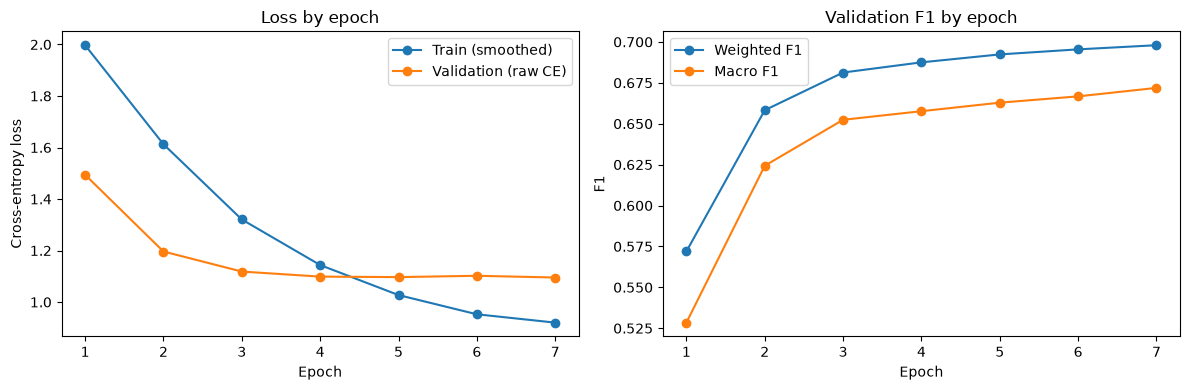

In [5]:
history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    'train_loss'        : '{:.4f}',
    'validation_loss'   : '{:.4f}',
    'accuracy'          : '{:.4f}',
    'weighted_f1'       : '{:.4f}',
    'macro_f1'          : '{:.4f}',
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame['global_epoch'], history_frame['train_loss'], marker='o', label='Train (smoothed)')
axes[0].plot(history_frame['global_epoch'], history_frame['validation_loss'], marker='o', label='Validation (raw CE)')
axes[0].set(title='Loss by epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()

axes[1].plot(history_frame['global_epoch'], history_frame['weighted_f1'], marker='o', label='Weighted F1')
axes[1].plot(history_frame['global_epoch'], history_frame['macro_f1'], marker='o', label='Macro F1')
axes[1].set(title='Validation F1 by epoch', xlabel='Epoch', ylabel='F1')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Evaluate with Test-Time Augmentation (TTA) and save probabilities

In [6]:
best = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best['model_state_dict'])

final_result = evaluate(
    model,
    validation_loader,
    eval_criterion,
    return_probabilities=True,
    use_tta=USE_TTA_IN_FINAL_EVAL,
)
prediction_frame, per_class = save_evaluation(final_result, '03_7_convnext_tiny_optimized')

Validation (TTA): 100%|██████████| 531/531 [00:42<00:00, 12.36it/s]


,validation_loss,accuracy,weighted_f1,macro_f1
03_7_convnext_tiny_optimized,1.0953,0.7031,0.6998,0.6752


,prdtypecode,precision,recall,f1,support
8,1281,0.416,0.362,0.387,414
7,1280,0.512,0.433,0.469,974
24,2585,0.522,0.461,0.489,499
6,1180,0.619,0.458,0.526,153
22,2582,0.545,0.519,0.532,518
17,2220,0.586,0.515,0.548,165
11,1302,0.555,0.546,0.551,498
2,50,0.564,0.548,0.556,336
16,2060,0.580,0.622,0.600,999
0,10,0.609,0.602,0.605,623


## 7. Auswertung & Fazit (Summary & Takeaways)

| Modell / Experiment | Accuracy | Weighted F1 | Macro F1 |
| :--- | :---: | :---: | :---: |
| `03_1` Baseline (`ResNet18` frozen) | `0.4832` | `0.4712` | `0.4150` |
| `03_4` `ResNet18` (Full + Regularized) | `0.6540` | `0.6509` | `0.6203` |
| `03_7` `ConvNeXt-Tiny` (Stage 3+4) | `0.6845` | `0.6819` | `0.6540` |
| **`03_7` `ConvNeXt-Tiny` (Full + SmartCrop + Sampler)** | **`0.7031`** | **`0.6998`** | **`0.6752`** |
| `04` Text allein (`LinearSVC` kalibriert) | `0.8350` | `0.8342` | `0.8168` |
| **`05` Fusion (`0.60` Text + `0.40` `03_7`)** | **`0.8659`** | **`0.8640`** | **`0.8548`** |

1. **Durchbruch über 70 % auf reinen Bilddaten:**
   Durch die Kombination aus vollständigem Fine-Tuning (`features[0..7]`) mit 4-stufigen Lernraten (`1e-5` bis `1e-4`), `SmartWhiteBorderCrop` und gedämpftem Minority-Oversampling (`WeightedRandomSampler`, `power=0.25`) steigt die Validierungs-Performance auf **70.31 % Accuracy**, **0.6998 Weighted F1** und **0.6752 Macro F1** (`+2.12 %-Punkte` beim Macro F1 gegenüber Teil-Finetuning von Stage 3+4).
2. **Wirkung von Smart-Cropping & Minority-Oversampling:**
   - **Croppen statt Verkleinern:** Kleine Katalogobjekte mit großem weißem Rand (`bbox_ratio < 0.75`) werden als nativer `224x224`-Ausschnitt in 1:1-Originalauflösung erhalten, während formatfüllende Fotos unverändert bleiben.
   - **Starker Zuwachs bei seltenen Klassen:** Unterrepräsentierte Klassen profitieren davon, dass sie über den Sampler pro Epoche häufiger gezogen und mit einheitlicher Augmentierung variiert werden, ohne dass Augmentierungs-Artefakte als Klassen-Shortcut geleakt werden. Der Validation-Loss sinkt über alle 7 Epochen stabil auf `1.0953` ohne Overfitting.
3. **Neuer Bestwert in der Text-Bild-Fusion (`05_fusion`):**
   In Kombination mit dem kalibrierten `LinearSVC`-Textmodell (`w = 0.60` Text, `0.40` Bild) erreicht die Fusion **0.8640 Weighted F1** (`+2.98 %-Punkte` gegenüber Text allein) und **0.8548 Macro F1** (`+3.80 %-Punkte` gegenüber Text allein).